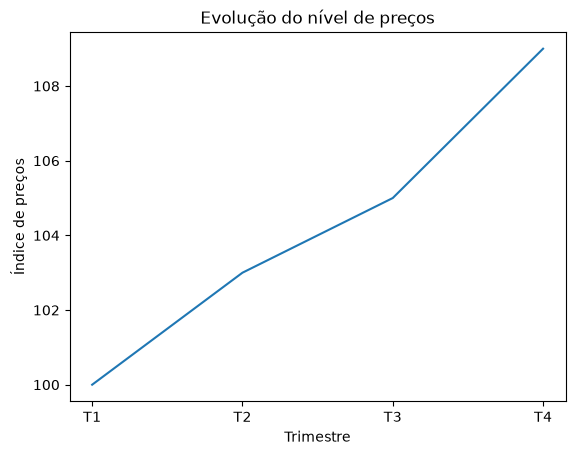

In [12]:

import matplotlib.pyplot as plt

trimestres = ['T1', 'T2', 'T3', 'T4']
precos = [100, 103, 105, 109]

fig, ax = plt.subplots()

ax.plot(trimestres, precos)

ax.set_title('Evolução do nível de preços')
ax.set_xlabel('Trimestre')
ax.set_ylabel('Índice de preços')

plt.show()


In [13]:
import pandas as pd
import numpy as np

df = pd.read_excel('dados/economi.xlsx')



df['P - nivel de precos'] = (df['M - oferta monetaria'] * df['V - velocidade'] ) / df['Y - produto real']


display(df.head())


,Trimestre,Ano,M - oferta monetaria,V - velocidade,Y - produto real,P - nivel de precos
0,2020T1,2020,103.665,0.98913,101.453,1.010696
1,2020T2,2020,107.297,0.97758,100.382,1.044922
2,2020T3,2020,111.334,0.95334,100.716,1.053846
3,2020T4,2020,115.307,0.94183,101.323,1.071816
4,2021T1,2021,117.442,0.94028,102.656,1.075713


In [14]:
df['Taxa de crescimento - M'] = df['M - oferta monetaria'].pct_change() * 100
df['Taxa de crescimento - V'] = df['V - velocidade'].pct_change() * 100
df['Taxa de crescimento - Y'] = df['Y - produto real'].pct_change() * 100
df['Taxa de crescimento - P'] = df['P - nivel de precos'].pct_change() * 100


df.head()


,Trimestre,Ano,M - oferta monetaria,V - velocidade,Y - produto real,P - nivel de precos,Taxa de crescimento - M,Taxa de crescimento - V,Taxa de crescimento - Y,Taxa de crescimento - P
0,2020T1,2020,103.665,0.98913,101.453,1.010696,NaN,NaN,NaN,NaN
1,2020T2,2020,107.297,0.97758,100.382,1.044922,3.503593,-1.167693,-1.055661,3.386399
2,2020T3,2020,111.334,0.95334,100.716,1.053846,3.762454,-2.479592,0.332729,0.853997
3,2020T4,2020,115.307,0.94183,101.323,1.071816,3.568542,-1.207334,0.602685,1.705162
4,2021T1,2021,117.442,0.94028,102.656,1.075713,1.851579,-0.164573,1.315595,0.363580


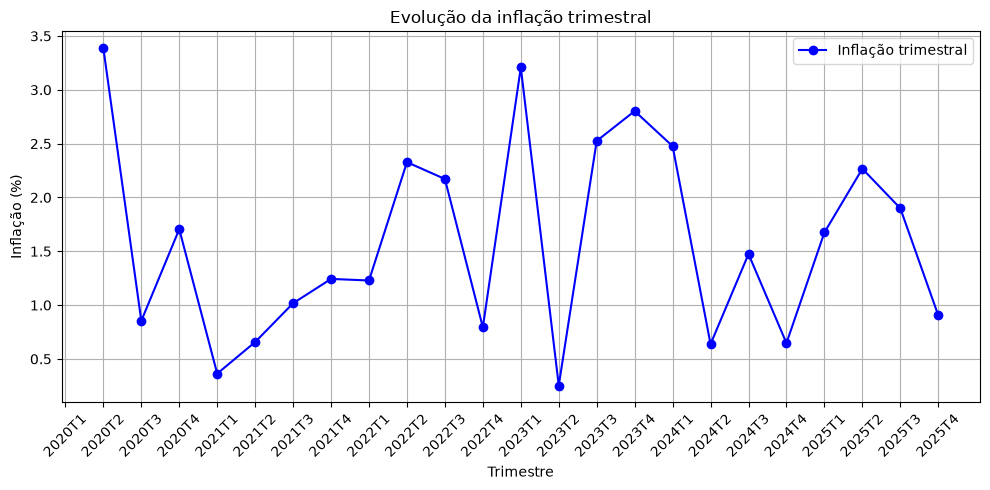

In [15]:
fig, ax = plt.subplots(figsize=(10,5))

ax.plot(
    df['Trimestre'],
    df['Taxa de crescimento - P'],
    label='Inflação trimestral',
    color='blue',
    marker='o'
)

ax.set_title('Evolução da inflação trimestral')
ax.set_xlabel('Trimestre')
ax.set_ylabel('Inflação (%)')
ax.legend()
ax.grid(True)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()



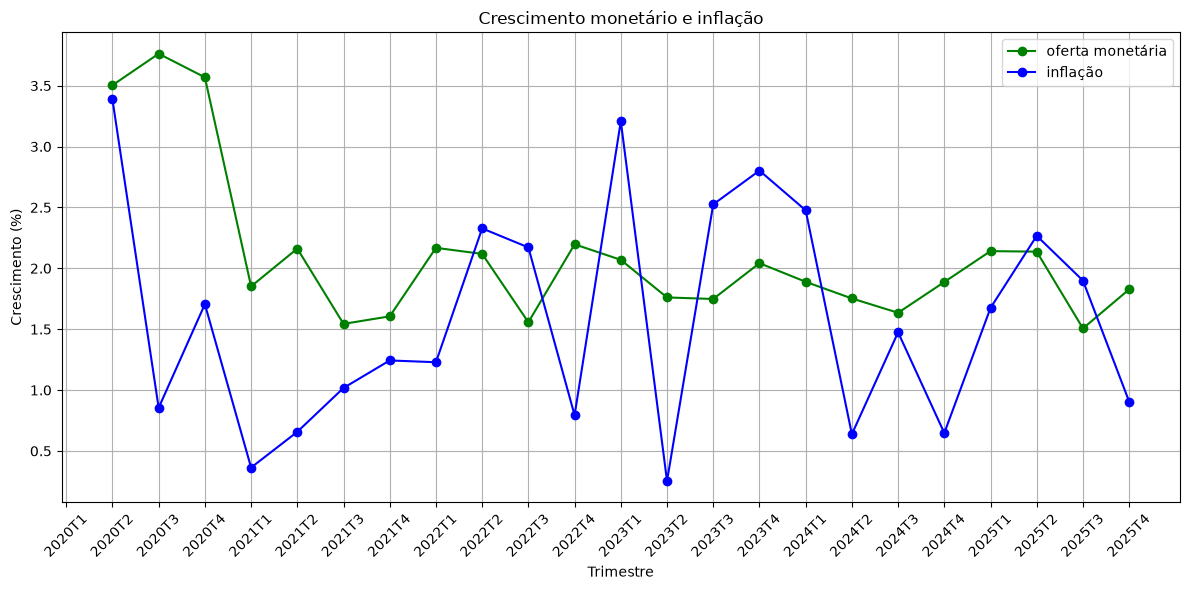

In [ ]:
#multiplas series

fig, ax = plt.subplots(figsize=(12,6))

ax.plot(
    df['Trimestre'],
    df['Taxa de crescimento - M'],
    label='oferta monetária',
    color='green',
    marker='o'
)

ax.plot(
    df['Trimestre'],
    df['Taxa de crescimento - P'],
    label='inflação',
    color='blue',
    marker='o'
)

ax.set_title('Crescimento monetário e inflação')
ax.set_xlabel('Trimestre')
ax.set_ylabel('Crescimento (%)')

ax.legend()
ax.grid(True)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


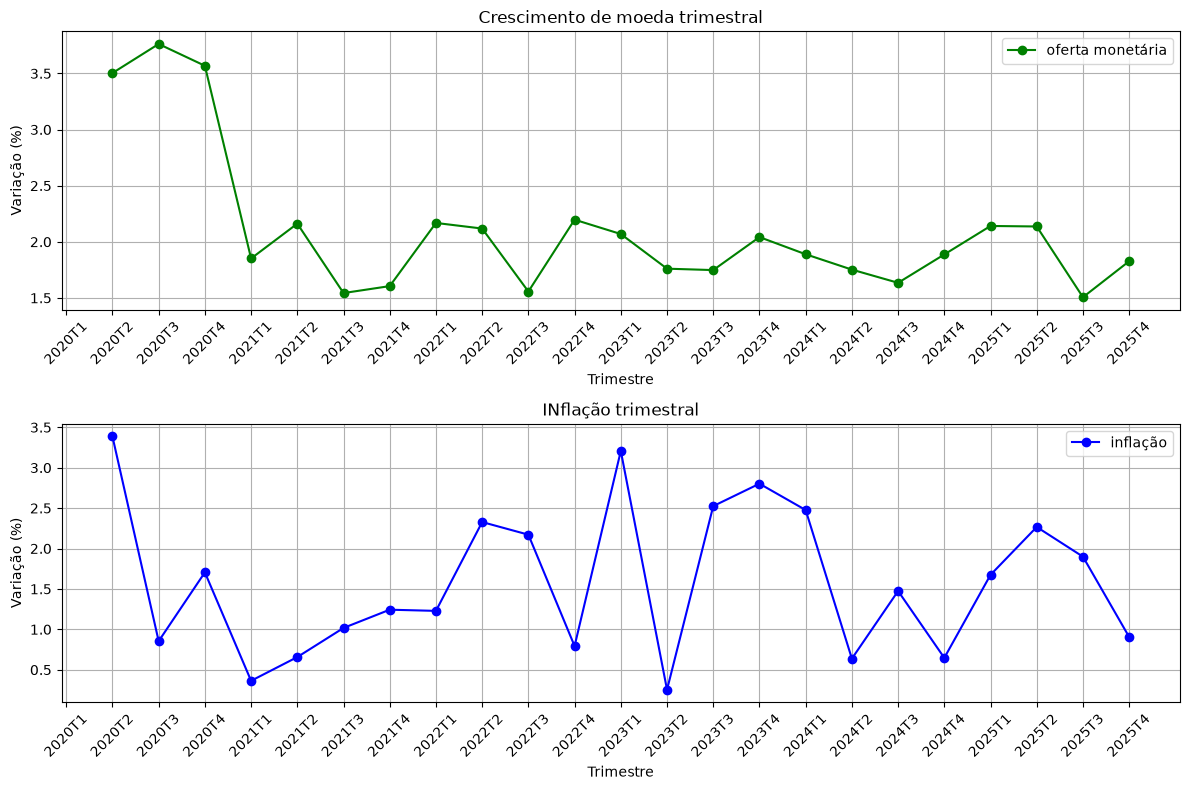

In [25]:
#criando vários gráficos na mesma figura

fig, axs = plt.subplots(2,1, figsize=(12,8)) # subplots(quantidade de linhas, qunatidade de colunas de graficos, figsize=(X,Y))


axs[0].plot(
    df['Trimestre'],
    df['Taxa de crescimento - M'],
    label='oferta monetária',
    color='green',
    marker='o'
)

axs[1].plot(
    df['Trimestre'],
    df['Taxa de crescimento - P'],
    label='inflação',
    color='blue',
    marker='o'
)

axs[0].set_title('Crescimento de moeda trimestral')
axs[0].set_ylabel('Variação (%)')
axs[0].set_xlabel('Trimestre')

axs[0].legend()

axs[1].set_title('INflação trimestral')
axs[1].set_ylabel('Variação (%)')
axs[1].set_xlabel('Trimestre')

axs[1].legend()

for ax in axs:
    ax.grid(True)
    ax.tick_params(axis='x', rotation=45)
    
plt.tight_layout()
plt.show()
    
    




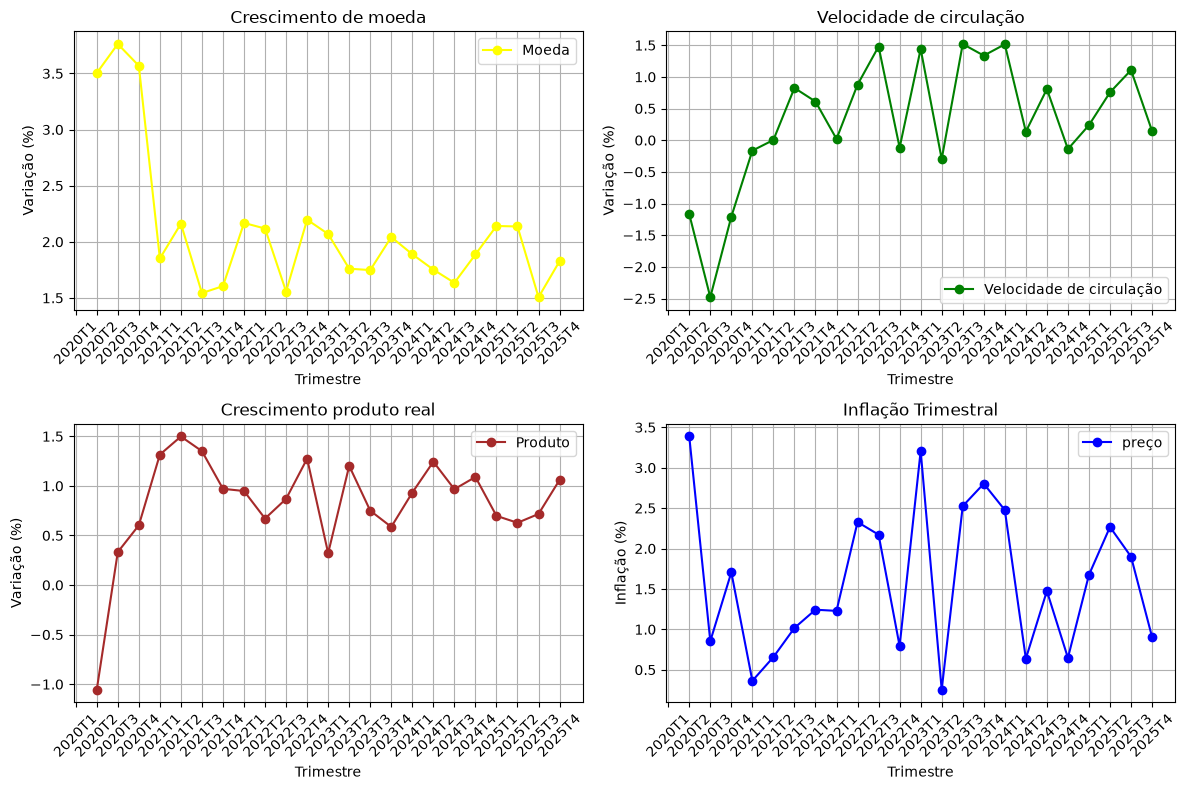

In [32]:
fig, axs = plt.subplots(2,2, figsize=(12,8))

axs[0, 0].plot(
    df['Trimestre'],
    df['Taxa de crescimento - M'],
    label='Moeda',
    color='yellow',
    marker='o'
)

axs[0, 1].plot(
    df['Trimestre'],
    df['Taxa de crescimento - V'],
    label='Velocidade de circulação',
    color='green',
    marker='o'
)

axs[1, 0].plot(
    df['Trimestre'],
    df['Taxa de crescimento - Y'],
    label='Produto',
    color='brown',
    marker='o'
)

axs[1, 1].plot(
    df['Trimestre'],
    df['Taxa de crescimento - P'],
    label='preço',
    color='blue',
    marker='o'   
)

axs[0, 0].set_title('Crescimento de moeda')
axs[0, 0].set_xlabel('Trimestre')
axs[0, 0].set_ylabel('Variação (%)')

axs[0, 0].legend()

axs[0, 1].set_title('Velocidade de circulação')
axs[0, 1].set_xlabel('Trimestre')
axs[0, 1].set_ylabel('Variação (%)')

axs[0, 1].legend()

axs[1, 0].set_title('Crescimento produto real')
axs[1, 0].set_xlabel('Trimestre')
axs[1, 0].set_ylabel('Variação (%)')

axs[1, 0].legend()

axs[1, 1].set_title('Inflação Trimestral')
axs[1, 1].set_xlabel('Trimestre')
axs[1, 1].set_ylabel('Inflação (%)')

axs[1, 1].legend()

for ax in axs.flatten():
    ax.grid(True)
    ax.tick_params(axis='x', rotation=45)
        
plt.tight_layout()
plt.show()

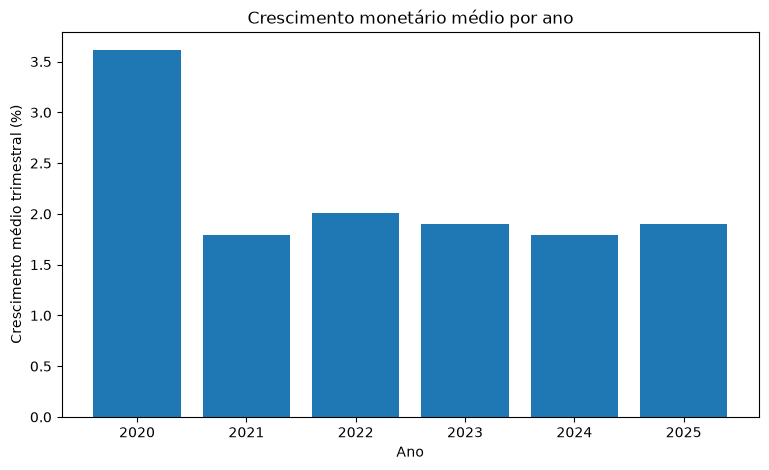

In [33]:
#graficos de barras

consolidando_gb = df.groupby('Ano')[
    [
        'Taxa de crescimento - M',
        'Taxa de crescimento - V',
        'Taxa de crescimento - Y',
        'Taxa de crescimento - P'
        ]
    ].mean()

fig , ax = plt.subplots(figsize=(9,5))

ax.bar(
    consolidando_gb.index,
    consolidando_gb['Taxa de crescimento - M']
)

ax.set_title('Crescimento monetário médio por ano')
ax.set_xlabel('Ano')
ax.set_ylabel('Crescimento médio trimestral (%)')

plt.show()



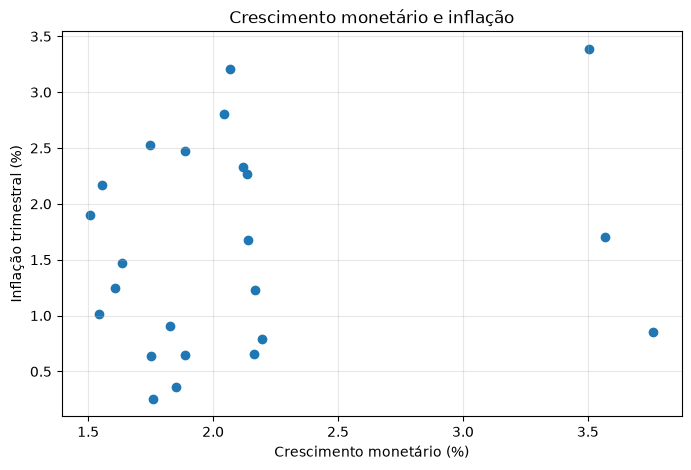

In [36]:
#gráfico de dispersao

# grafico interessante para investigar relações entre variaveis quantitativas

fig, ax = plt.subplots(figsize=(8,5))

ax.scatter(
    df['Taxa de crescimento - M'],
    df['Taxa de crescimento - P']
)

ax.set_title('Crescimento monetário e inflação')
ax.set_xlabel('Crescimento monetário (%)')
ax.set_ylabel('Inflação trimestral (%)')

ax.grid(True, alpha=0.3)
plt.show()

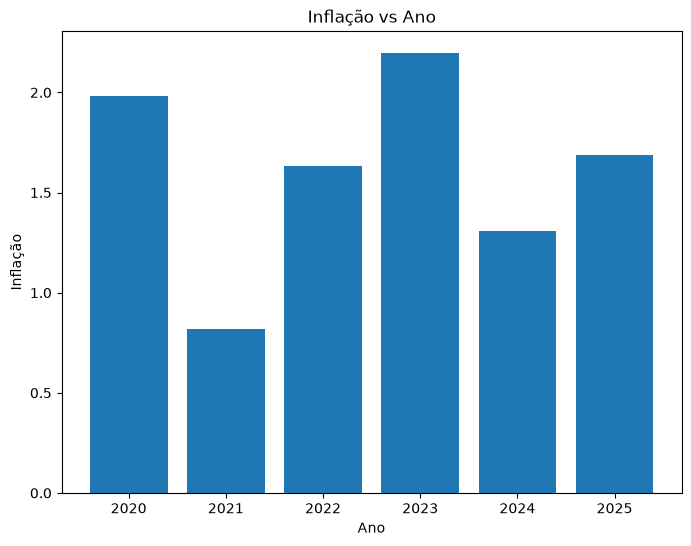

In [40]:
#Gráfico de barras: compare a inflação média trimestral por ano, utilizando groupby() e mean().

inflacao_media = df.groupby('Ano')['Taxa de crescimento - P'].mean()

fig, ax = plt.subplots(figsize=(8,6))

ax.bar(
    inflacao_media.index,
    inflacao_media
    
)

ax.set_title('Inflação vs Ano')
ax.set_xlabel('Ano')
ax.set_ylabel('Inflação')

plt.show()


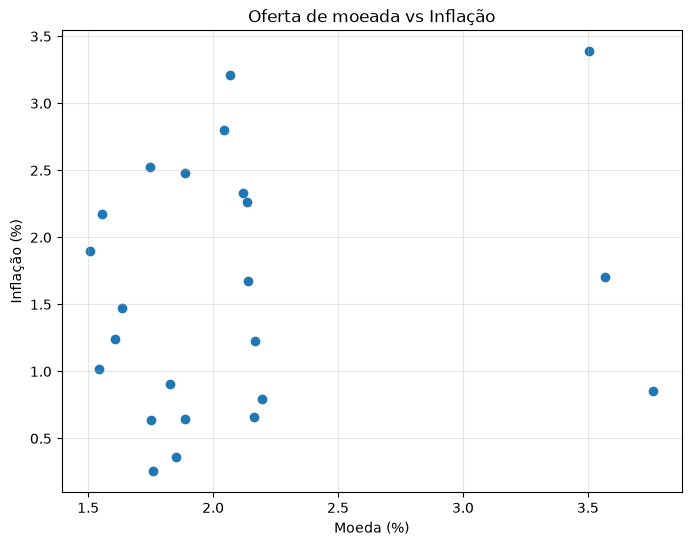

In [ ]:
#Gráfico de dispersão: represente o crescimento da oferta monetária no eixo X e a inflação trimestral no eixo Y.

fig, ax = plt.subplots(figsize=(8,6))

ax.scatter(
    df['Taxa de crescimento - M'],
    df['Taxa de crescimento - P']
)

ax.set_title('Oferta de moeda vs Inflação')
ax.set_xlabel('Moeda (%)')
ax.set_ylabel('Inflação (%)')


ax.grid(True, alpha=0.3)
plt.show()

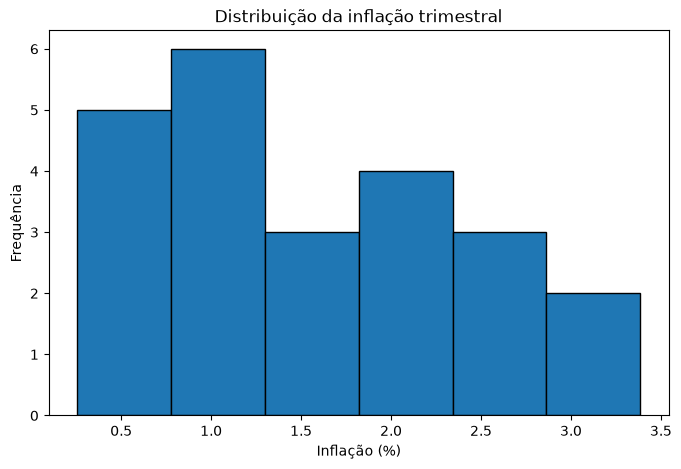

In [ ]:
#histograma

fig, ax = plt.subplots(figsize=(8,5))

ax.hist(
    df['Taxa de crescimento - P'].dropna(), #dropna, remove valores ausente da serie
    bins=6, #DIVIDE O VALOR EM SEIS INTERVALOS
    edgecolor='black'
)

ax.set_title('Distribuição da inflação trimestral')
ax.set_xlabel('Inflação (%)')
ax.set_ylabel('Frequência')

plt.show()

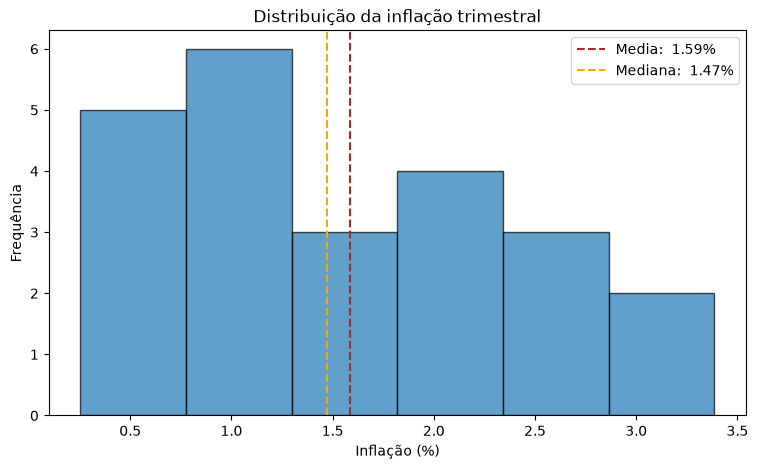

In [45]:
inflacao = df['Taxa de crescimento - P'].dropna()

media = inflacao.mean()
mediana = inflacao.median()

fig, ax = plt.subplots(figsize=(9,5))

ax.hist(
    inflacao,
    bins=6,
    edgecolor='black',
    alpha=0.7
)

ax.axvline(
    media,
    color='brown',
    linestyle='--',
    label= f'Media: {media: .2f}%'
)

ax.axvline(
    mediana,
    color='orange',
    linestyle='--',
    label= f'Mediana: {mediana: .2f}%'
)

ax.set_title('Distribuição da inflação trimestral')
ax.set_xlabel('Inflação (%)')
ax.set_ylabel('Frequência')
ax.legend()

plt.show()